# 05 · The Embedders II — Bidirectional LSTM with GloVe Initialisation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/05_bilstm.ipynb)

`04_static_embeddings` showed that the GloVe vectors cover the vocabulary well but that their **order-free average** is a weak sentence representation. This notebook keeps the same pre-trained vectors and replaces the average with a **bidirectional LSTM** (Lecture 7), which reads the words in order and learns how to combine them.

| Model id | Embedding layer | Sentence encoder | Classifier |
|---|---|---|---|
| `bilstm_frozen` | GloVe (selected in `04`), **fixed** | BiLSTM, last forward ⊕ last backward hidden state | linear + softmax |
| `bilstm_finetuned` | GloVe (selected in `04`), **updated** by back-propagation | same | same |
| `bilstm` | role name: the variant selected on validation | | |

The model code (vocabulary, dataset, model class and training loop) is in `src/bilstm.py`. Questions answered here:

1. Frozen vs fine-tuned embeddings: does adapting the pre-trained vectors to the emotion labels help, and how much do the vectors move? (§5–6, controlled comparison over three random seeds)
2. Adding word order and a learned composition: how much does the BiLSTM gain over averaged GloVe with the *same* embeddings, and over the best sparse model? (§7)
3. Does the BiLSTM actually use word order? (§8: shuffled-word test, length, negation and minimal pairs)

Training uses the training split, early stopping uses validation macro-F1, and the test split is used once, in §7–8. On a Mac the model is trained on the Apple-silicon GPU (`mps`); the same notebook runs on CUDA (Colab) or the CPU.

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides every package this notebook needs; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import json
import time
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score, log_loss

from src import bilstm
from src.bilstm import (
    BiLSTMClassifier,
    TrainConfig,
    build_embedding_matrix,
    build_vocabulary,
    collate_batch,
    count_parameters,
    get_device,
    load_checkpoint,
    predict_proba,
    save_checkpoint,
)
from src.config import EMOTION_COLORS, FIG_DIR, LABELS, METRICS_DIR, MODELS_DIR, PRED_DIR, SEED, ensure_dirs, set_seed
from src.data import load_splits, tokenize
from src.embeddings import load_glove
from src.evaluate import (
    evaluate,
    mcnemar_test,
    paired_bootstrap,
    plot_confusion_matrix,
    plot_per_class_f1,
    summary_table,
)
from src.slices import has_negation, training_vocabulary, unseen_word_mask

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

BILSTM_DIR = MODELS_DIR / "bilstm"
BILSTM_DIR.mkdir(parents=True, exist_ok=True)
CLASSICAL_DIR = MODELS_DIR / "classical"
LABEL_IDS = list(range(len(LABELS)))

# Apple-silicon GPU if available, then CUDA, then CPU. Use get_device("cpu") to force the CPU.
DEVICE = get_device()
print(f"PyTorch {torch.__version__} | device: {DEVICE}")


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary selection metric: unweighted mean of the six per-class F1 scores.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

PyTorch 2.15.0 | device: mps


## 1. Data and reference models

The reference models are the best sparse model of Step 3 (`improved_lr`) and the averaged-GloVe model of Step 4 (`glove_lr`); their saved predictions are used for the paired tests, and their pipelines for the behavioural probes in §8.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]

X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()
tokens = {name: [tokenize(t) for t in X] for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]}
train_vocab = training_vocabulary(X_train)  # shared definition from src/slices.py (Step 3)

REFERENCE = {"tfidf_lr": "TF-IDF + LR", "improved_lr": "Improved sparse LR", "glove_lr": "GloVe + LR"}
missing = [m for m in REFERENCE for s in ("validation", "test") if not (PRED_DIR / f"{m}__{s}.csv").exists()]
assert not missing, f"Run 02, 03 and 04 first; missing predictions for {missing}"
reference_preds = {
    split: {m: pd.read_csv(PRED_DIR / f"{m}__{split}.csv")["pred"].to_numpy() for m in REFERENCE}
    for split in ("validation", "test")
}
reference_models = {m: joblib.load(CLASSICAL_DIR / f"{m}.joblib") for m in ("improved_lr", "glove_lr")}

selection_04 = json.loads((METRICS_DIR / "selection_static_embeddings.json").read_text())
GLOVE_NAME = selection_04["selected_variant"]
glove = load_glove(GLOVE_NAME)
print(f"GloVe table selected in 04: {GLOVE_NAME} ({len(glove):,} types, {glove.dim} dimensions)")

GloVe table selected in 04: wiki300 (318,650 types, 300 dimensions)


## 2. Recurrent sequence models (Lecture 7)

### 2.1 From bags to sequences

Every model so far has been order-free: *i was scared but now i feel relieved* and *i was relieved but now i feel scared* receive the same representation. A **recurrent neural network** reads the tokens $x_1, \dots, x_n$ one at a time and updates a hidden state that summarises the prefix read so far,

$$
\mathbf{h}_t = \tanh(W_{xh}\,\mathbf{e}_{x_t} + W_{hh}\,\mathbf{h}_{t-1} + \mathbf{b}_h),
$$

where $\mathbf{e}_{x_t}$ is the embedding of token $x_t$. The same weights are applied at every position, so the network can process texts of any length. Training back-propagates through all time steps; repeated multiplication by $W_{hh}$ makes gradients **vanish or explode** over long sequences.

### 2.2 Long short-term memory

The **LSTM** adds a memory cell $\mathbf{c}_t$ and three gates that decide what to forget, what to write and what to expose:

$$
\begin{aligned}
\mathbf{f}_t &= \sigma(W_f[\mathbf{h}_{t-1}; \mathbf{e}_{x_t}] + \mathbf{b}_f) && \text{forget gate}\\
\mathbf{i}_t &= \sigma(W_i[\mathbf{h}_{t-1}; \mathbf{e}_{x_t}] + \mathbf{b}_i) && \text{input gate}\\
\tilde{\mathbf{c}}_t &= \tanh(W_c[\mathbf{h}_{t-1}; \mathbf{e}_{x_t}] + \mathbf{b}_c) && \text{candidate memory}\\
\mathbf{c}_t &= \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t && \text{additive cell update}\\
\mathbf{o}_t &= \sigma(W_o[\mathbf{h}_{t-1}; \mathbf{e}_{x_t}] + \mathbf{b}_o), \qquad \mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t) && \text{output gate}
\end{aligned}
$$

Because the cell is updated additively, information (and gradient) can flow over many steps when $\mathbf{f}_t \approx 1$.

### 2.3 Bidirectional encoder and classifier

A **bidirectional** LSTM runs one LSTM left-to-right and a second one right-to-left. The sentence vector is the concatenation of the last forward state $\overrightarrow{\mathbf{h}}_n$ (which has read the whole text) and the last backward state $\overleftarrow{\mathbf{h}}_1$ (which has also read the whole text, in reverse), followed by dropout and a linear layer with softmax:

$$
\mathbf{s} = [\overrightarrow{\mathbf{h}}_n ; \overleftarrow{\mathbf{h}}_1] \in \mathbb{R}^{2H}, \qquad P(y \mid x) = \operatorname{softmax}(W\mathbf{s} + \mathbf{b}).
$$

The loss is the cross-entropy with balanced class weights (the weighting chosen for the sparse model in Step 3). Mini-batches are padded only to their longest text (**dynamic padding**), and `pack_padded_sequence` makes the LSTM skip the padding, so $\overrightarrow{\mathbf{h}}_n$ is the state after the last *real* word.

### 2.4 Fixed hyper-parameters

The architecture is fixed in advance rather than searched, so that the frozen vs fine-tuned comparison is not confounded by a different search for each setting:

| | value | reason |
|---|---|---|
| embedding | GloVe, 300-d (from `04`) | same table as `glove_lr` |
| LSTM | 1 layer, $H$ = 128 per direction | ~16K training texts; a second layer adds capacity the data cannot support |
| dropout | 0.5 on embeddings and on $\mathbf{s}$ | standard for small text classification sets |
| optimiser | Adam, learning rate $10^{-3}$, batch 64, gradient-norm clipping at 5 | guards against exploding gradients (§2.1) |
| stopping | max 30 epochs; stop after 4 epochs without a gain in validation macro-F1; restore the best epoch | early stopping is the model-selection step |

## 3. Vocabulary and embedding matrix

The vocabulary contains every training word type, plus pre-trained words that do not occur in training:

* the 20,000 most frequent GloVe words, so that the saved model also recognises common words that a user of the web app may type;
* the GloVe words that occur in the validation and test texts. No labels are involved, and this is only a memory-saving way of loading the full 400K-word table: a row that never occurs in a training batch never receives a gradient, so it keeps its GloVe value in both the frozen and the fine-tuned model — exactly as if the complete table had been loaded. §6 verifies this.

Training words without a GloVe vector are initialised randomly with the same scale as the GloVe values; `<pad>` (index 0) is a zero vector and `<unk>` (index 1) stands for any word outside the vocabulary.

In [4]:
APP_EXTRA_WORDS = 20_000
eval_words = [w for split in ("validation", "test") for toks in tokens[split] for w in toks if w in glove.index]
vocab = build_vocabulary(X_train, extra_words=glove.words[:APP_EXTRA_WORDS] + eval_words)
embedding_matrix, from_glove = build_embedding_matrix(vocab, glove, seed=SEED)

n_train_words = len(train_vocab)
train_rows = np.arange(2, 2 + n_train_words)  # training words follow <pad> and <unk>
assert set(vocab.itos[2:2 + n_train_words]) == train_vocab
vocab_stats = pd.Series({
    "vocabulary size |V|": len(vocab),
    "training word types": n_train_words,
    "training types initialised from GloVe": int(from_glove[train_rows].sum()),
    "training types initialised randomly": int((~from_glove[train_rows]).sum()),
    "extra GloVe words (never in a training batch)": len(vocab) - 2 - n_train_words,
    "embedding matrix shape": tuple(embedding_matrix.shape),
})
display(vocab_stats.to_frame("value"))

for split in ("validation", "test"):
    unk = np.mean([vocab.stoi.get(w, 1) == 1 for toks in tokens[split] for w in toks])
    print(f"{split:<10} tokens mapped to <unk>: {unk:.2%}")

,value
vocabulary size |V|,27008
training word types,15212
training types initialised from GloVe,14212
training types initialised randomly,1000
extra GloVe words (never in a training batch),11794
embedding matrix shape,"(27008, 300)"


validation tokens mapped to <unk>: 0.28%
test       tokens mapped to <unk>: 0.30%


In [5]:
# One mini-batch, to make the tensor shapes of the Lecture 7 example concrete.
example = [X_train[i] for i in (0, 1, 2)]
batch = [(torch.tensor(vocab.encode(t)), int(y_train[i])) for i, t in zip((0, 1, 2), example)]
text, text_lengths, labels = collate_batch(batch)
for t, ids in zip(example, text):
    print(f"{t[:60]:<60} -> {ids[:10].tolist()} ...")
print(f"\ntext {tuple(text.shape)} (batch, longest length) | text_lengths {text_lengths.tolist()} | labels {labels.tolist()}")

i didnt feel humiliated                                      -> [2, 139, 3, 679, 0, 0, 0, 0, 0, 0] ...
i can go from feeling so hopeless to so damned hopeful just  -> [2, 40, 101, 60, 8, 15, 494, 5, 15, 3496] ...
im grabbing a minute to post i feel greedy wrong             -> [17, 3060, 7, 1149, 5, 286, 2, 3, 495, 438] ...

text (3, 21) (batch, longest length) | text_lengths [4, 21, 10] | labels [0, 0, 3]


## 4. Model

The same class is instantiated twice; only `freeze_embeddings` differs. Freezing removes the embedding matrix from the trainable parameters, so the frozen model learns about 0.44M weights while the fine-tuned model also adapts 8.1M embedding values (27,008 words × 300 dimensions).

In [6]:
CONFIGS = {
    "bilstm_frozen": TrainConfig(glove=GLOVE_NAME, freeze_embeddings=True, notes="GloVe embeddings frozen"),
    "bilstm_finetuned": TrainConfig(glove=GLOVE_NAME, freeze_embeddings=False, notes="GloVe embeddings fine-tuned"),
}
DISPLAY_NAMES = {**REFERENCE, "bilstm_frozen": "BiLSTM (frozen GloVe)", "bilstm_finetuned": "BiLSTM (fine-tuned GloVe)"}

print(BiLSTMClassifier(len(vocab), glove.dim, hidden_dim=128))
param_table = pd.DataFrame({
    model_id: count_parameters(BiLSTMClassifier(len(vocab), glove.dim, cfg.hidden_dim,
                                                freeze_embeddings=cfg.freeze_embeddings))
    for model_id, cfg in CONFIGS.items()
}).T
display(param_table.style.format("{:,.0f}"))

BiLSTMClassifier(
  (embedding): Embedding(27008, 300, padding_idx=0)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=6, bias=True)
)


,trainable,total
bilstm_frozen,"441,862","8,544,262"
bilstm_finetuned,"8,544,262","8,544,262"


## 5. Training with early stopping

Each configuration is trained with three random seeds (42, 43, 44). The seed changes the initial LSTM weights, the dropout masks and the order of the mini-batches, so the spread across seeds shows how much of a difference between the two settings could come from training noise alone — something a single run and a test-set significance test cannot show. The seed-42 run of each setting is the reported model (the project seed).

Checkpoints are written to `models/bilstm/`. With `RETRAIN = False`, an existing checkpoint and its training history are loaded instead of retraining, so the notebook can be re-run quickly.

In [7]:
SEEDS = [42, 43, 44]
RETRAIN = False
HISTORY_FILE = METRICS_DIR / "bilstm_training_history.csv"

histories = pd.read_csv(HISTORY_FILE) if HISTORY_FILE.exists() and not RETRAIN else pd.DataFrame()
runs = {}  # (model_id, seed) -> trained model
for model_id, base_cfg in CONFIGS.items():
    for seed in SEEDS:
        cfg = TrainConfig(**{**base_cfg.__dict__, "seed": seed})
        path = BILSTM_DIR / (f"{model_id}.pt" if seed == SEED else f"{model_id}_seed{seed}.pt")
        known = (not histories.empty) and ((histories["model"] == model_id) & (histories["seed"] == seed)).any()
        if path.exists() and known and not RETRAIN:
            runs[model_id, seed] = load_checkpoint(path, DEVICE)[0]
            print(f"loaded {path.name}")
            continue
        print(f"\n=== {model_id} | seed {seed} ===")
        start = time.perf_counter()
        model, history = bilstm.fit(cfg, vocab, embedding_matrix, (X_train, y_train), (X_val, y_val), DEVICE)
        print(f"best epoch {history['best_epoch'].iloc[0]} | {time.perf_counter() - start:.0f}s")
        save_checkpoint(path, model, vocab, cfg, extra={"best_epoch": int(history["best_epoch"].iloc[0])})
        runs[model_id, seed] = model
        history.insert(0, "seed", seed)
        history.insert(0, "model", model_id)
        if not histories.empty:
            histories = histories[~((histories["model"] == model_id) & (histories["seed"] == seed))]
        histories = pd.concat([histories, history], ignore_index=True)
        histories.to_csv(HISTORY_FILE, index=False)


=== bilstm_frozen | seed 42 ===
epoch  1  train loss 1.5892  val loss 1.1002  val macro-F1 0.4806  *  (11s)
epoch  2  train loss 1.0223  val loss 0.6507  val macro-F1 0.7234  *  (7s)
epoch  3  train loss 0.7266  val loss 0.4509  val macro-F1 0.8085  *  (7s)
epoch  4  train loss 0.6011  val loss 0.3904  val macro-F1 0.8159  *  (7s)
epoch  5  train loss 0.5157  val loss 0.3335  val macro-F1 0.8376  *  (7s)
epoch  6  train loss 0.4510  val loss 0.2891  val macro-F1 0.8519  *  (7s)
epoch  7  train loss 0.4092  val loss 0.2624  val macro-F1 0.8757  *  (7s)
epoch  8  train loss 0.3638  val loss 0.2316  val macro-F1 0.8729  (7s)
epoch  9  train loss 0.3353  val loss 0.2188  val macro-F1 0.8784  *  (7s)
epoch 10  train loss 0.3058  val loss 0.2160  val macro-F1 0.8824  *  (7s)
epoch 11  train loss 0.2852  val loss 0.2331  val macro-F1 0.8762  (7s)
epoch 12  train loss 0.2715  val loss 0.2189  val macro-F1 0.8827  *  (7s)
epoch 13  train loss 0.2483  val loss 0.2199  val macro-F1 0.8900  *  (7

### 5.1 Learning curves

The left panel shows the cross-entropy loss of the seed-42 runs on the training split (measured after each epoch with dropout off) and on the validation split; the right panel the validation macro-F1 of all seeds. The dotted line marks the epoch restored by early stopping.

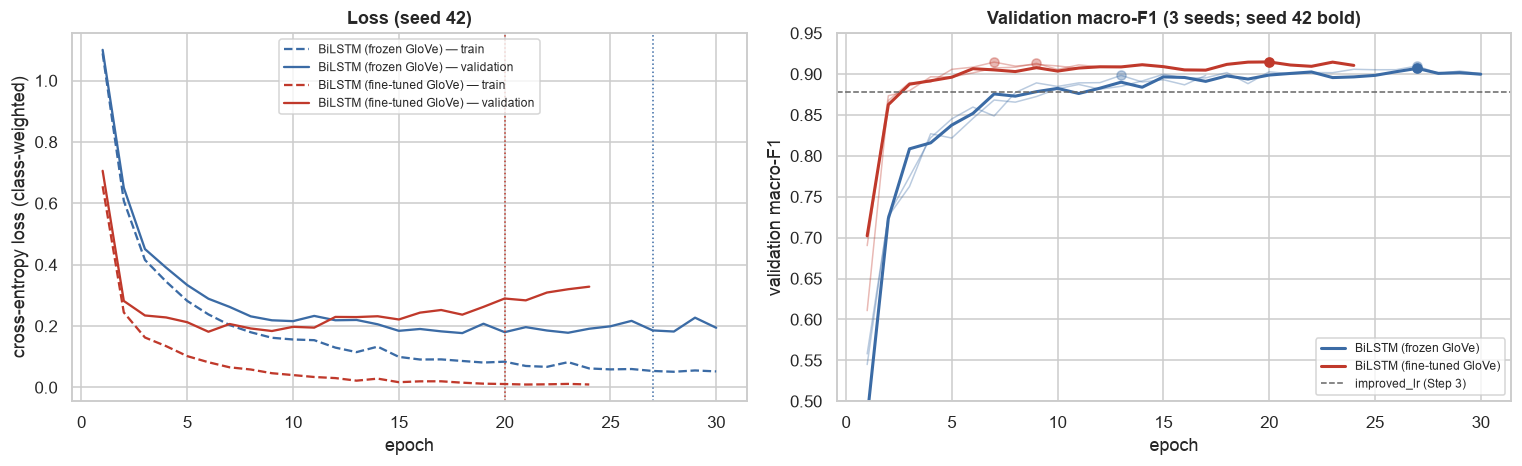

In [8]:
colors = {"bilstm_frozen": "#3B6BA5", "bilstm_finetuned": "#C0392B"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for model_id in CONFIGS:
    h = histories[(histories["model"] == model_id) & (histories["seed"] == SEED)]
    axes[0].plot(h["epoch"], h["train_loss_eval"], "--", color=colors[model_id], label=f"{DISPLAY_NAMES[model_id]} — train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=colors[model_id], label=f"{DISPLAY_NAMES[model_id]} — validation")
    axes[0].axvline(h["best_epoch"].iloc[0], color=colors[model_id], ls=":", lw=1)
    for seed in SEEDS:
        hs = histories[(histories["model"] == model_id) & (histories["seed"] == seed)]
        axes[1].plot(hs["epoch"], hs["val_macro_f1"], "-", color=colors[model_id],
                     alpha=1.0 if seed == SEED else 0.35, lw=2 if seed == SEED else 1,
                     label=DISPLAY_NAMES[model_id] if seed == SEED else None)
        best_row = hs.loc[hs["val_macro_f1"].idxmax()]
        axes[1].plot(best_row["epoch"], best_row["val_macro_f1"], "o", color=colors[model_id], alpha=1.0 if seed == SEED else 0.35)
sparse_val_f1 = summary_table(["improved_lr"], split="validation")["macro_f1"].iloc[0]
axes[1].axhline(sparse_val_f1, color="0.4", ls="--", lw=1, label="improved_lr (Step 3)")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss (class-weighted)", title="Loss (seed 42)")
axes[1].set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 (3 seeds; seed 42 bold)",
            ylim=(0.5, 0.95))
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "bilstm_learning_curves.png")
plt.show()

### 5.2 Frozen vs fine-tuned on validation

In [9]:
best_rows = histories.loc[histories.groupby(["model", "seed"])["val_macro_f1"].idxmax()]
per_seed = best_rows.pivot(index="seed", columns="model", values="val_macro_f1")[list(CONFIGS)]
seed_summary = pd.DataFrame({
    "val macro-F1 (seed 42)": per_seed.loc[SEED],
    "val macro-F1 mean": per_seed.mean(),
    "val macro-F1 sd": per_seed.std(ddof=1),
    "best epoch (per seed)": best_rows.groupby("model")["epoch"].apply(lambda s: ", ".join(map(str, s))),
    "seconds per epoch": histories.groupby("model")["seconds"].mean(),
    "trainable parameters": param_table["trainable"],
}).loc[list(CONFIGS)]
seed_summary.index = [DISPLAY_NAMES[m] for m in seed_summary.index]
display(seed_summary.style.format({"val macro-F1 (seed 42)": "{:.4f}", "val macro-F1 mean": "{:.4f}",
                                   "val macro-F1 sd": "{:.4f}", "seconds per epoch": "{:.1f}",
                                   "trainable parameters": "{:,.0f}"}))

selected_id = max(CONFIGS, key=lambda m: per_seed[m].mean())
print(f"Selected on validation (mean over seeds): {selected_id} -> role name 'bilstm'")

,val macro-F1 (seed 42),val macro-F1 mean,val macro-F1 sd,best epoch (per seed),seconds per epoch,trainable parameters
BiLSTM (frozen GloVe),0.9069,0.9050,0.0060,"27, 27, 13",6.9,"441,862"
BiLSTM (fine-tuned GloVe),0.9148,0.9141,0.0009,"20, 9, 7",8.8,"8,544,262"


Selected on validation (mean over seeds): bilstm_finetuned -> role name 'bilstm'


## 6. What fine-tuning does to the embedding space

Fine-tuning lets the emotion labels reshape the vectors. Three checks on the seed-42 fine-tuned model:

1. Rows of words that never occur in a training batch are unchanged (the claim made in §3).
2. How far each training word has moved, measured by the cosine similarity between its GloVe vector and its fine-tuned vector, by training frequency.
3. Whether emotion words of opposite polarity have moved apart.

In [10]:
E_glove = embedding_matrix.numpy()
E_tuned = runs["bilstm_finetuned", SEED].embedding.weight.detach().cpu().numpy()
E_frozen = runs["bilstm_frozen", SEED].embedding.weight.detach().cpu().numpy()

extra_rows = np.arange(2 + n_train_words, len(vocab))
assert np.array_equal(E_frozen, E_glove), "frozen embeddings changed"
assert np.array_equal(E_tuned[extra_rows], E_glove[extra_rows]), "rows outside the training vocabulary changed"
print(f"check 1 passed: {len(extra_rows):,} rows of non-training words are identical to GloVe after fine-tuning")


def cosine_rows(A, B):
    return np.sum(A * B, axis=1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-8)


train_counts = Counter(w for toks in tokens["train"] for w in toks)
glove_train_rows = train_rows[from_glove[train_rows]]
drift = pd.DataFrame({
    "word": [vocab.itos[i] for i in glove_train_rows],
    "train count": [train_counts[vocab.itos[i]] for i in glove_train_rows],
    "cos(GloVe, fine-tuned)": cosine_rows(E_glove[glove_train_rows], E_tuned[glove_train_rows]),
})
drift["frequency band"] = pd.cut(drift["train count"], [0, 1, 5, 50, 500, np.inf],
                                 labels=["1", "2–5", "6–50", "51–500", "> 500"])
display(drift.groupby("frequency band", observed=True)["cos(GloVe, fine-tuned)"].describe()[["count", "mean", "min"]].round(3))

frequent = drift[drift["train count"] >= 50].nsmallest(12, "cos(GloVe, fine-tuned)")
print("Frequent words (≥ 50 training occurrences) that moved most:")
print(", ".join(f"{w} ({c:.2f})" for w, c in zip(frequent["word"], frequent["cos(GloVe, fine-tuned)"])))

check 1 passed: 11,794 rows of non-training words are identical to GloVe after fine-tuning


,count,mean,min
frequency band,,,
1,6865.0,0.992,0.907
2–5,4298.0,0.989,0.847
6–50,2373.0,0.978,0.857
51–500,593.0,0.959,0.785
> 500,83.0,0.976,0.946


Frequent words (≥ 50 training occurrences) that moved most:
convinced (0.78), determined (0.81), resolved (0.86), disturbed (0.86), divine (0.86), broke (0.86), fake (0.86), ok (0.87), innocent (0.87), liked (0.87), popular (0.87), rushed (0.87)


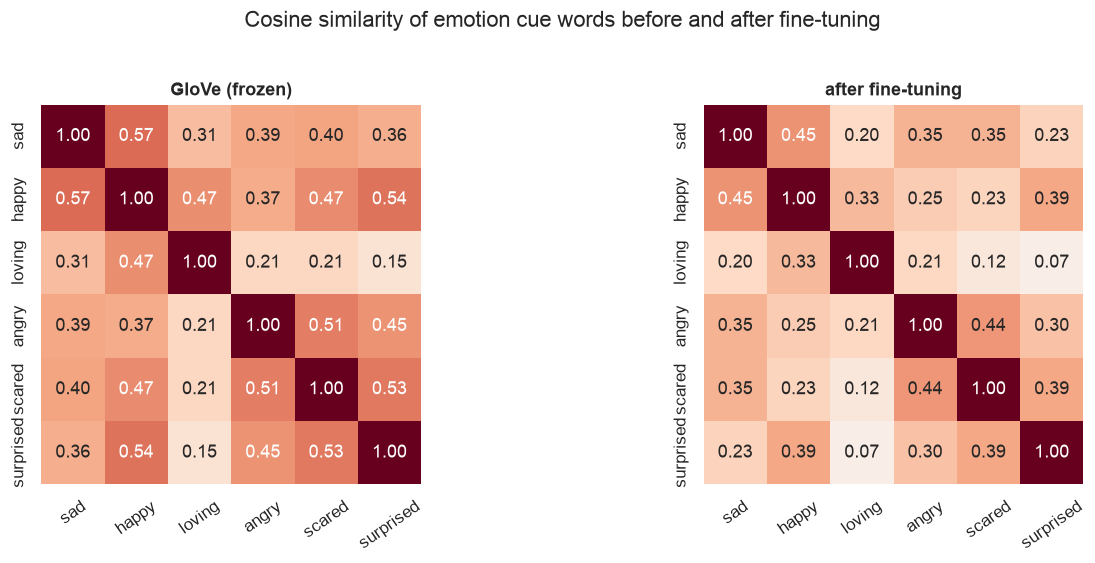

,GloVe,fine-tuned
sad,"sorry, tragic, happy, unfortunate, terribly, pathetic","tragic, sorry, unfortunate, pathetic, awful, melancholy"
happy,"glad, pleased, really, always, everyone, feel","glad, pleased, sure, delighted, thrilled, proud"
loving,"caring, love, loved, passionate, gentle, dad","caring, gentle, loved, fond, lovely, supportive"
angry,"outraged, frustrated, annoyed, anger, agitated, frightened","outraged, frustrated, annoyed, impatient, disgusted, agitated"
scared,"frightened, afraid, terrified, worried, fearful, tired","frightened, afraid, terrified, fearful, intimidated, confused"
surprised,"disappointed, pleased, shocked, stunned, impressed, amazed","impressed, shocked, stunned, amazed, curious, delighted"


In [11]:
CUES = ["sad", "happy", "loving", "angry", "scared", "surprised"]
cue_rows = [vocab.stoi[w] for w in CUES]


def cue_similarity(E):
    U = E[cue_rows] / np.linalg.norm(E[cue_rows], axis=1, keepdims=True)
    return pd.DataFrame(U @ U.T, index=CUES, columns=CUES)


def neighbours(E, word, k=6):
    # Nearest neighbours among training words seen at least 20 times.
    pool = np.array([vocab.stoi[w] for w, c in train_counts.items() if c >= 20 and w != word])
    U = E[pool] / np.linalg.norm(E[pool], axis=1, keepdims=True)
    q = E[vocab.stoi[word]] / np.linalg.norm(E[vocab.stoi[word]])
    return ", ".join(vocab.itos[pool[j]] for j in np.argsort(-(U @ q))[:k])


fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, (title, E) in zip(axes, [("GloVe (frozen)", E_glove), ("after fine-tuning", E_tuned)]):
    sns.heatmap(cue_similarity(E), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.tick_params(axis="x", rotation=35)
    ax.set_title(title)
fig.suptitle("Cosine similarity of emotion cue words before and after fine-tuning", y=1.02)
fig.tight_layout()
savefig(fig, "bilstm_finetuned_cue_similarity.png")
plt.show()

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"GloVe": {w: neighbours(E_glove, w) for w in CUES},
                          "fine-tuned": {w: neighbours(E_tuned, w) for w in CUES}}))

## 7. Test evaluation

### 7.1 Scores

The seed-42 model of each setting is scored through `src/evaluate.py` on validation and test, and the selected setting is saved again under the role name `bilstm` (metrics, predictions and `models/bilstm/bilstm.pt` for the web service). The test scores of seeds 43 and 44 are reported as well, to show the training variance on the test split; they play no part in any selection.

In [12]:
preds, probas = {"validation": {}, "test": {}}, {"validation": {}, "test": {}}
for model_id, cfg in CONFIGS.items():
    model = runs[model_id, SEED]
    best_epoch = int(best_rows[(best_rows["model"] == model_id) & (best_rows["seed"] == SEED)]["epoch"].iloc[0])
    notes = (f"BiLSTM (1 layer, H={cfg.hidden_dim} per direction, dropout {cfg.dropout}) on {GLOVE_NAME} GloVe, "
             f"{'frozen' if cfg.freeze_embeddings else 'fine-tuned'} embeddings; class-weighted cross-entropy; "
             f"Adam lr={cfg.lr}; early stopping on validation macro-F1 (best epoch {best_epoch}); seed {SEED}")
    for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        proba = predict_proba(model, vocab, X, DEVICE)
        pred = proba.argmax(axis=1)
        evaluate(model_id, y, pred, split=split, y_proba=proba, texts=X, notes=notes)
        preds[split][model_id], probas[split][model_id] = pred, proba

DISPLAY_NAMES["bilstm"] = f"BiLSTM [selected: {'frozen' if CONFIGS[selected_id].freeze_embeddings else 'fine-tuned'}]"
for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    evaluate("bilstm", y, preds[split][selected_id], split=split, y_proba=probas[split][selected_id], texts=X,
             notes=f"role name: {selected_id} (selected by mean validation macro-F1 over seeds {SEEDS})", verbose=False)
    preds[split]["bilstm"], probas[split]["bilstm"] = preds[split][selected_id], probas[split][selected_id]
save_checkpoint(BILSTM_DIR / "bilstm.pt", runs[selected_id, SEED], vocab, CONFIGS[selected_id],
                extra={"role": "bilstm", "model_id": selected_id})
print(f"models/bilstm/bilstm.pt  {(BILSTM_DIR / 'bilstm.pt').stat().st_size / 2**20:.1f} MB")

seed_test = pd.DataFrame({
    model_id: {seed: macro_f1(y_test, predict_proba(runs[model_id, seed], vocab, X_test, DEVICE).argmax(1)) for seed in SEEDS}
    for model_id in CONFIGS
})
seed_test.loc["mean"], seed_test.loc["sd"] = seed_test.loc[SEEDS].mean(), seed_test.loc[SEEDS].std(ddof=1)
print("Test macro-F1 by seed (reported only, not used for selection)")
display(seed_test.rename(columns=DISPLAY_NAMES).round(4))

bilstm_frozen [validation]  accuracy=0.9300  macro-F1=0.9069  weighted-F1=0.9310
bilstm_frozen [test]  accuracy=0.9215  macro-F1=0.8876  weighted-F1=0.9236
bilstm_finetuned [validation]  accuracy=0.9410  macro-F1=0.9148  weighted-F1=0.9416
bilstm_finetuned [test]  accuracy=0.9315  macro-F1=0.8939  weighted-F1=0.9329
models/bilstm/bilstm.pt  33.0 MB
Test macro-F1 by seed (reported only, not used for selection)


,BiLSTM (frozen GloVe),BiLSTM (fine-tuned GloVe)
42,0.8876,0.8939
43,0.8930,0.8922
44,0.8660,0.8879
mean,0.8822,0.8913
sd,0.0143,0.0031


In [13]:
LADDER = ["tfidf_lr", "improved_lr", "glove_lr", "bilstm_frozen", "bilstm_finetuned"]
print("Validation split")
display(summary_table(["dummy_most_frequent", "dummy_stratified"] + LADDER, split="validation").round(3))

test_preds = {**reference_preds["test"], **preds["test"]}


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled test sets.
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


test_table = summary_table(LADDER, split="test")
ci = {name: bootstrap_ci(y_test, test_preds[name]) for name in LADDER}
test_table.insert(2, "macro_f1_ci95", [f"[{ci[n][0]:.3f}, {ci[n][1]:.3f}]" for n in LADDER])
print("Test split (final evaluation)")
display(test_table.round(3))

Validation split


,accuracy,macro_f1,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,
dummy_most_frequent,0.352,0.087,0.183,0.000,0.521,0.000,0.000,0.000,0.000
dummy_stratified,0.244,0.171,0.244,0.297,0.349,0.092,0.144,0.094,0.052
tfidf_lr,0.894,0.865,0.894,0.912,0.924,0.826,0.897,0.834,0.797
improved_lr,0.899,0.878,0.900,0.924,0.918,0.850,0.905,0.846,0.825
glove_lr,0.697,0.642,0.694,0.713,0.767,0.599,0.646,0.605,0.524
bilstm_frozen,0.930,0.907,0.931,0.958,0.947,0.887,0.931,0.880,0.838
bilstm_finetuned,0.941,0.915,0.942,0.972,0.959,0.888,0.948,0.881,0.841


Test split (final evaluation)


,accuracy,macro_f1,macro_f1_ci95,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,,
tfidf_lr,0.882,0.832,"[0.808, 0.853]",0.880,0.919,0.910,0.761,0.876,0.833,0.694
improved_lr,0.885,0.843,"[0.820, 0.862]",0.888,0.925,0.910,0.774,0.886,0.860,0.701
glove_lr,0.674,0.601,"[0.573, 0.629]",0.671,0.709,0.741,0.503,0.620,0.606,0.429
bilstm_frozen,0.922,0.888,"[0.867, 0.905]",0.924,0.959,0.942,0.831,0.923,0.878,0.792
bilstm_finetuned,0.932,0.894,"[0.873, 0.911]",0.933,0.965,0.953,0.861,0.936,0.885,0.764


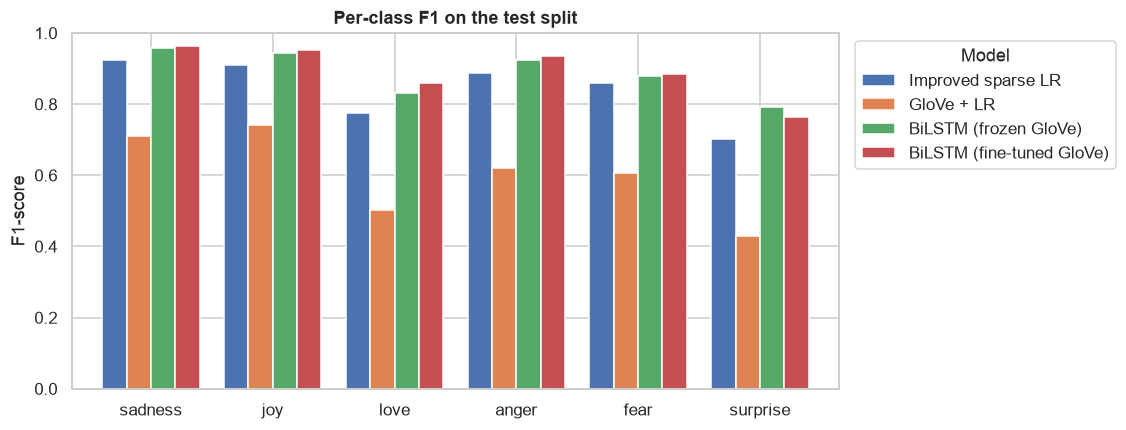

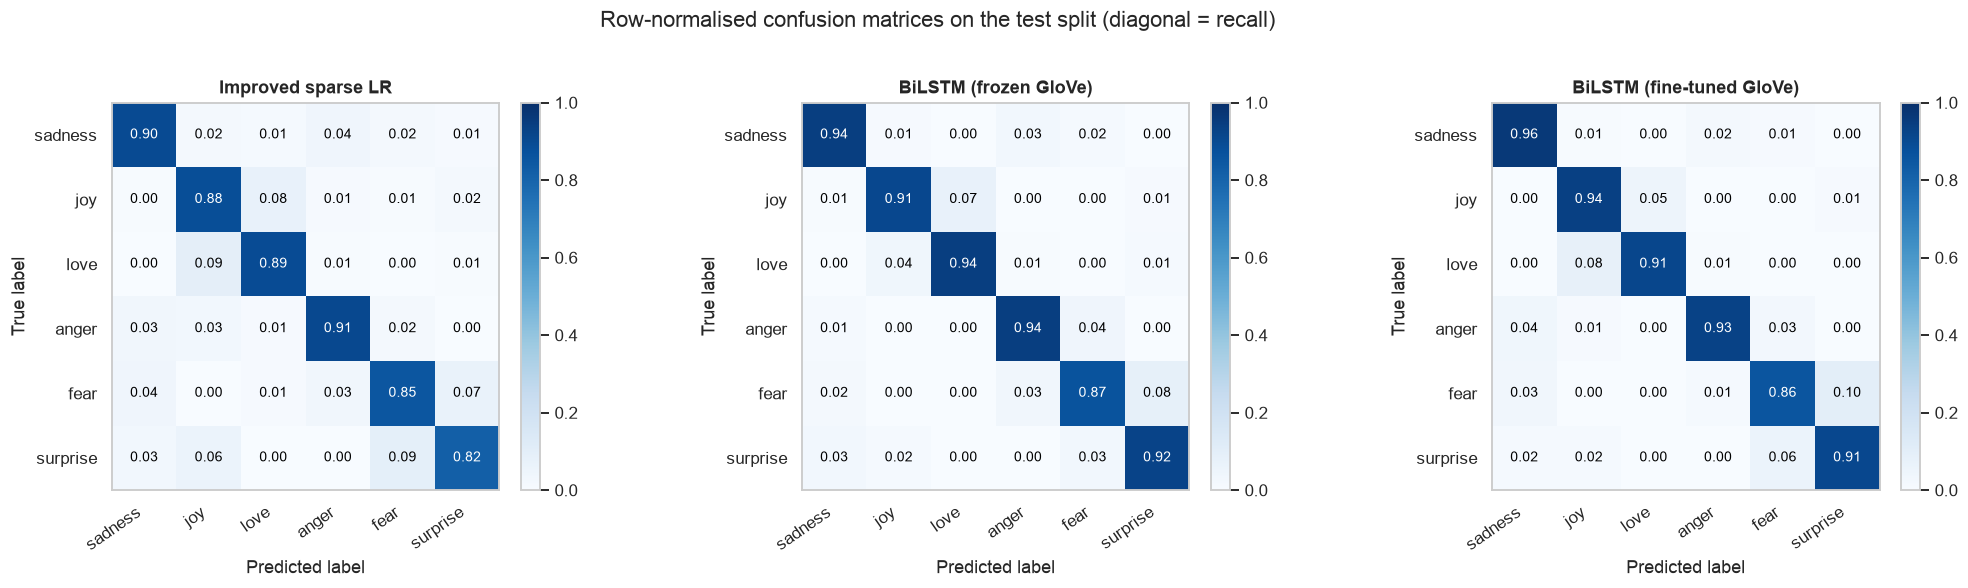

In [14]:
ax = plot_per_class_f1(
    test_table.drop(columns="macro_f1_ci95").loc[["improved_lr", "glove_lr", "bilstm_frozen", "bilstm_finetuned"]].rename(index=DISPLAY_NAMES),
    title="Per-class F1 on the test split",
    save_as="bilstm_per_class_f1.png",
)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, name in zip(axes, ["improved_lr", "bilstm_frozen", "bilstm_finetuned"]):
    plot_confusion_matrix(y_test, test_preds[name], title=DISPLAY_NAMES[name], ax=ax)
fig.suptitle("Row-normalised confusion matrices on the test split (diagonal = recall)", y=1.02)
fig.tight_layout()
savefig(fig, "bilstm_confusion_matrices.png")
plt.show()

### 7.2 Significance of the controlled comparisons

Paired tests on the 2,000 test texts as before (McNemar's test; paired bootstrap of the macro-F1 difference with 2,000 resamples), Holm-adjusted for the three comparisons. The tests treat each trained model as fixed; the seed spread in §5.2 and §7.1 complements them with the variance due to training.

In [15]:
def holm(p_values):
    # Holm step-down adjustment of a list of p-values (controls the family-wise error rate).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


COMPARISONS = [
    ("bilstm_frozen", "bilstm_finetuned", "frozen → fine-tuned GloVe (same BiLSTM)"),
    ("glove_lr", "bilstm_frozen", "averaged → BiLSTM-composed GloVe (same frozen vectors): word order + learned composition"),
    ("improved_lr", "bilstm", "best sparse model (Step 3) → selected BiLSTM"),
]
test_preds["bilstm"] = preds["test"]["bilstm"]

rows = []
for a, b, question in COMPARISONS:
    mc = mcnemar_test(y_test, test_preds[a], test_preds[b])
    bs = paired_bootstrap(y_test, test_preds[a], test_preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{DISPLAY_NAMES[a]} → {DISPLAY_NAMES[b]}",
        "question": question,
        "b (only A correct)": mc["b"],
        "c (only B correct)": mc["c"],
        "McNemar p": mc["p_value"],
        "Δ macro-F1": bs["delta"],
        "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
    })
significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.insert(5, "Holm p", holm(significance["McNemar p"]))
significance.to_csv(METRICS_DIR / "significance_bilstm_test.csv")
display(significance.style.format({"McNemar p": "{:.2g}", "Holm p": "{:.2g}", "Δ macro-F1": "{:+.3f}"}))

,question,b (only A correct),c (only B correct),McNemar p,Δ macro-F1,Holm p,95% CI of Δ
comparison (A → B),,,,,,,
BiLSTM (frozen GloVe) → BiLSTM (fine-tuned GloVe),frozen → fine-tuned GloVe (same BiLSTM),43,63,0.065,+0.006,0.065,"[-0.009, +0.022]"
GloVe + LR → BiLSTM (frozen GloVe),averaged → BiLSTM-composed GloVe (same frozen vectors): word order + learned composition,63,557,3e-87,+0.286,9e-87,"[+0.256, +0.315]"
Improved sparse LR → BiLSTM [selected: fine-tuned],best sparse model (Step 3) → selected BiLSTM,32,125,2.1e-13,+0.051,4.2e-13,"[+0.036, +0.068]"


## 8. Does the BiLSTM use word order?

A higher score alone does not show *why* the BiLSTM is better. Four probes separate the contribution of word order from that of a better composition function.

### 8.1 Shuffled-word test

Every test text is rebuilt with its words in a random order (five different permutations). Bag-of-words and averaged-GloVe models are, by construction, unaffected. The drop of the BiLSTM measures how much of its accuracy depends on the order of the words; whatever survives the shuffle is what it gains from learning *which* words matter.

In [16]:
rng = np.random.default_rng(SEED)
N_PERMUTATIONS = 5
shuffle_rows = []
for k in range(N_PERMUTATIONS):
    shuffled = [" ".join(rng.permutation(toks)) for toks in tokens["test"]]
    for model_id in CONFIGS:
        pred = predict_proba(runs[model_id, SEED], vocab, shuffled, DEVICE).argmax(axis=1)
        shuffle_rows.append({"model": model_id, "permutation": k, "macro_f1": macro_f1(y_test, pred)})
    shuffle_rows.append({"model": "glove_lr", "permutation": k,
                         "macro_f1": macro_f1(y_test, reference_models["glove_lr"].predict(shuffled))})

shuffle_scores = pd.DataFrame(shuffle_rows).groupby("model")["macro_f1"].agg(["mean", "std"])
order_table = pd.DataFrame({
    "original order": {m: macro_f1(y_test, test_preds[m]) for m in ["glove_lr", *CONFIGS]},
    "shuffled (mean of 5)": shuffle_scores["mean"],
    "sd over permutations": shuffle_scores["std"],
})
order_table["drop"] = order_table["shuffled (mean of 5)"] - order_table["original order"]
order_table.index = [DISPLAY_NAMES[m] for m in order_table.index]
order_table.to_csv(METRICS_DIR / "word_order_shuffle_test.csv")
display(order_table.round(4))

,original order,shuffled (mean of 5),sd over permutations,drop
BiLSTM (fine-tuned GloVe),0.8939,0.8080,0.0107,-0.0859
BiLSTM (frozen GloVe),0.8876,0.7395,0.0125,-0.1481
GloVe + LR,0.6015,0.6015,0.0000,0.0000


### 8.2 Text length and negation

`04` showed that the averaged-GloVe model loses most on long texts. A recurrent encoder can, in principle, keep the important words in its state regardless of how many template words surround them. The negation slice (texts that contain a negation cue, `src.slices.has_negation`, defined in `01_eda` and shared since Step 3) is where word order should matter most: *not happy* and *happy* share their only content word.

,n,Improved sparse LR,GloVe + LR,BiLSTM (frozen GloVe),BiLSTM (fine-tuned GloVe),Δ bilstm − improved_lr,95% CI of Δ
test slice,,,,,,,
length 3–10,501,0.892,0.727,0.897,0.888,-0.004,"[-0.034, +0.029]"
length 11–17,531,0.877,0.606,0.879,0.897,0.020,"[-0.009, +0.051]"
length 18–26,507,0.838,0.561,0.889,0.875,0.037,"[+0.007, +0.069]"
length 27–61,461,0.758,0.492,0.886,0.912,0.155,"[+0.110, +0.202]"
with negation cue,570,0.813,0.587,0.883,0.906,0.092,"[+0.057, +0.130]"
without negation cue,1430,0.855,0.609,0.890,0.890,0.034,"[+0.015, +0.054]"
contains an unseen word,630,0.835,0.508,0.898,0.915,0.080,"[+0.046, +0.116]"
all words seen in training,1370,0.845,0.642,0.881,0.880,0.035,"[+0.017, +0.053]"


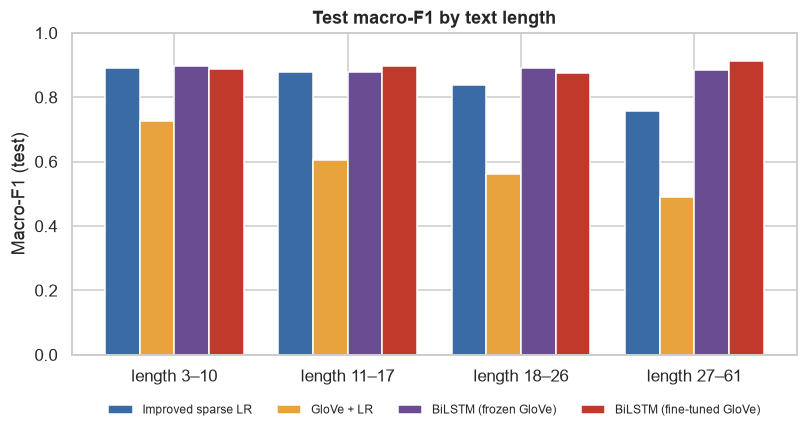

In [17]:
test_lengths = np.array([len(toks) for toks in tokens["test"]])
length_bins = pd.qcut(test_lengths, 4)
negation_mask = has_negation(X_test)
has_unseen = unseen_word_mask(X_test, train_vocab)

slices = [(f"length {int(np.floor(iv.left)) + 1}–{iv.right:.0f}", length_bins == iv) for iv in length_bins.categories]
slices += [("with negation cue", negation_mask), ("without negation cue", ~negation_mask),
           ("contains an unseen word", has_unseen), ("all words seen in training", ~has_unseen)]
SLICE_MODELS = ["improved_lr", "glove_lr", "bilstm_frozen", "bilstm_finetuned"]

slice_rows = []
for slice_name, mask in slices:
    row = {"test slice": slice_name, "n": int(mask.sum())}
    row.update({DISPLAY_NAMES[m]: macro_f1(y_test[mask], test_preds[m][mask]) for m in SLICE_MODELS})
    bs = paired_bootstrap(y_test[mask], test_preds["improved_lr"][mask], test_preds["bilstm"][mask], n_boot=2000, seed=SEED)
    row["Δ bilstm − improved_lr"] = bs["delta"]
    row["95% CI of Δ"] = f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]"
    slice_rows.append(row)
slice_table = pd.DataFrame(slice_rows).set_index("test slice")
slice_table.to_csv(METRICS_DIR / "slices_bilstm_test.csv")
display(slice_table.round(3))

length_part = slice_table.iloc[:4]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(length_part))
palette = ["#3B6BA5", "#E8A33D", "#6A4C93", "#C0392B"]
for k, (m, color) in enumerate(zip(SLICE_MODELS, palette)):
    ax.bar(x + (k - 1.5) * 0.2, length_part[DISPLAY_NAMES[m]], width=0.2, color=color, label=DISPLAY_NAMES[m])
ax.set_xticks(x, length_part.index)
ax.set_ylim(0, 1)
ax.set_ylabel("Macro-F1 (test)")
ax.set_title("Test macro-F1 by text length")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
savefig(fig, "bilstm_length_slices.png")
plt.show()

### 8.3 Minimal pairs

Each pair below differs only in word order or in a negation. For the swapped pairs, both sentences contain exactly the same words, so every order-free model — bag of words, TF-IDF and averaged GloVe — must give both sentences the same prediction. These hand-written sentences are an illustration, not a test set; the systematic behavioural tests follow in `08_error_analysis`.

In [18]:
PAIRS = [
    ("i was scared at first but now i feel relieved and happy", "i was relieved and happy at first but now i feel scared"),
    ("i am not angry just really surprised", "i am not surprised just really angry"),
    ("i feel happy", "i do not feel happy"),
    ("i feel loved", "i don t feel loved anymore"),
]
probe_models = {
    "improved_lr": lambda texts: reference_models["improved_lr"].predict(texts),
    "glove_lr": lambda texts: reference_models["glove_lr"].predict(texts),
    "bilstm_frozen": lambda texts: predict_proba(runs["bilstm_frozen", SEED], vocab, texts, DEVICE).argmax(1),
    "bilstm_finetuned": lambda texts: predict_proba(runs["bilstm_finetuned", SEED], vocab, texts, DEVICE).argmax(1),
}
probe_texts = [t for pair in PAIRS for t in pair]
probe = pd.DataFrame({DISPLAY_NAMES[m]: [LABELS[i] for i in f(probe_texts)] for m, f in probe_models.items()}, index=probe_texts)
probe.insert(0, "pair", [f"{k // 2 + 1}{'ab'[k % 2]}" for k in range(len(probe_texts))])
with pd.option_context("display.max_colwidth", 80):
    display(probe)

,pair,Improved sparse LR,GloVe + LR,BiLSTM (frozen GloVe),BiLSTM (fine-tuned GloVe)
i was scared at first but now i feel relieved and happy,1a,joy,joy,joy,joy
i was relieved and happy at first but now i feel scared,1b,joy,joy,fear,fear
i am not angry just really surprised,2a,surprise,anger,surprise,surprise
i am not surprised just really angry,2b,surprise,anger,anger,surprise
i feel happy,3a,joy,joy,joy,joy
i do not feel happy,3b,joy,joy,joy,joy
i feel loved,4a,love,love,love,love
i don t feel loved anymore,4b,love,love,love,love


## 9. Probability quality

The web application displays class probabilities, so their calibration matters. Neural networks trained with cross-entropy are often over-confident. **Temperature scaling** (Guo et al., 2017) divides the logits by one scalar $T$ fitted on the validation split; it changes the confidence, never the predicted label. Because $\log p_c = z_c - \log\sum_k e^{z_k}$, scaling the log-probabilities by $1/T$ and re-normalising is the same as scaling the logits.

In [19]:
def apply_temperature(proba, T):
    logits = np.log(np.clip(proba, 1e-12, 1.0)) / T
    logits -= logits.max(axis=1, keepdims=True)
    scaled = np.exp(logits)
    return scaled / scaled.sum(axis=1, keepdims=True)


temperatures, calibration_rows = {}, []
for model_id in CONFIGS:
    fit_T = minimize_scalar(lambda T: log_loss(y_val, apply_temperature(probas["validation"][model_id], T), labels=LABEL_IDS),
                            bounds=(0.05, 10.0), method="bounded")
    temperatures[model_id] = float(fit_T.x)
    for label, proba in [("raw", probas["test"][model_id]), ("temperature-scaled", apply_temperature(probas["test"][model_id], fit_T.x))]:
        confidence = proba.max(axis=1)
        correct = proba.argmax(axis=1) == y_test
        calibration_rows.append({
            "model": DISPLAY_NAMES[model_id], "probabilities": label, "T": fit_T.x if label != "raw" else 1.0,
            "test log-loss": log_loss(y_test, proba, labels=LABEL_IDS), "mean confidence": confidence.mean(),
            "accuracy": correct.mean(), "wrong with confidence > 0.9": int(np.sum(~correct & (confidence > 0.9))),
        })
temperatures["bilstm"] = temperatures[selected_id]
(METRICS_DIR / "temperature_bilstm.json").write_text(json.dumps(temperatures, indent=2))
display(pd.DataFrame(calibration_rows).set_index(["model", "probabilities"]).round(3))

T  test log-loss  \
model                     probabilities                              
BiLSTM (frozen GloVe)     raw                 1.000          0.209   
                          temperature-scaled  1.458          0.183   
BiLSTM (fine-tuned GloVe) raw                 1.000          0.249   
                          temperature-scaled  2.053          0.172   

                                              mean confidence  accuracy  \
model                     probabilities                                   
BiLSTM (frozen GloVe)     raw                           0.962     0.922   
                          temperature-scaled            0.943     0.922   
BiLSTM (fine-tuned GloVe) raw                           0.977     0.932   
                          temperature-scaled            0.947     0.932   

                                              wrong with confidence > 0.9  
model                     probabilities                                    
BiLSTM (frozen GloVe)     raw                                          46  
                          temperature-scaled                           23  
BiLSTM (fine-tuned GloVe) raw                                          73  
                          temperature-scaled                           30

## 10. Saved model for the web service

`models/bilstm/bilstm.pt` contains the weights, the vocabulary and the training configuration; `load_checkpoint` rebuilds the model and `predict_proba` accepts raw strings. The check below reloads the file on the CPU (as the FastAPI service will) and compares it with the in-memory model.

In [20]:
service_model, service_vocab, ckpt = load_checkpoint(BILSTM_DIR / "bilstm.pt", torch.device("cpu"))
service_proba = predict_proba(service_model, service_vocab, X_test, torch.device("cpu"))
agreement = np.mean(service_proba.argmax(1) == preds["test"]["bilstm"])
print(f"reloaded on CPU: {ckpt['extra']} | label agreement with the {DEVICE} run: {agreement:.4f} | "
      f"max |Δp| = {np.abs(service_proba - probas['test']['bilstm']).max():.1e}")

demo = ["i feel so lonely without you", "i am thrilled about the trip", "i was shocked by the news", "i feel forlorn"]
demo_proba = pd.DataFrame(apply_temperature(predict_proba(service_model, service_vocab, demo, torch.device("cpu")),
                                            temperatures["bilstm"]), columns=LABELS, index=demo).round(3)
demo_proba["prediction"] = [LABELS[i] for i in demo_proba[LABELS].to_numpy().argmax(1)]
demo_proba

reloaded on CPU: {'role': 'bilstm', 'model_id': 'bilstm_finetuned'} | label agreement with the mps run: 1.0000 | max |Δp| = 1.7e-06


,sadness,joy,love,anger,fear,surprise,prediction
i feel so lonely without you,0.996,0.000,0.000,0.002,0.001,0.000,sadness
i am thrilled about the trip,0.018,0.914,0.028,0.011,0.008,0.021,joy
i was shocked by the news,0.046,0.027,0.011,0.015,0.043,0.859,surprise
i feel forlorn,0.269,0.170,0.184,0.177,0.102,0.098,sadness


## 11. Discussion

### 11.1 Overall results

The BiLSTM is the first model of the project above 0.85 test macro-F1. With frozen GloVe vectors it reaches 0.922 accuracy and 0.888 macro-F1 [0.867, 0.905] on the test split; with fine-tuned vectors 0.932 and 0.894 [0.873, 0.911]. The selected model (fine-tuned, higher mean validation macro-F1) is significantly better than the best sparse model of Step 3: Δ macro-F1 = +0.051 [+0.036, +0.068]; 125 test texts are classified correctly only by the BiLSTM and 32 only by `improved_lr` (McNemar p ≈ 2e-13, Holm-adjusted 4e-13). The gain is largest for the confusable minority class *love* (test F1 0.77 → 0.86) and for *surprise* (0.70 → 0.76), while *sadness* and *joy* gain about 0.04 each.

### 11.2 Frozen vs fine-tuned embeddings

Fine-tuning gives a small and consistent advantage on validation but no significant difference on test. Over three seeds, the fine-tuned setting reaches 0.9141 ± 0.0009 validation macro-F1 and the frozen setting 0.9050 ± 0.0060. On test, the seed-42 models score 0.894 and 0.888 (seed means 0.891 and 0.882), but McNemar's test does not reject equal accuracy (63 vs 43 discordant texts, p = 0.065) and the macro-F1 difference is +0.006 [−0.009, +0.022]. The clearest difference is **stability**: the frozen model's test score varies more across seeds (sd 0.014, with one seed at 0.866) than the fine-tuned model's (sd 0.003).

What else fine-tuning changes:

* **Cost and overfitting.** It trains 19 times more parameters (8.5M vs 0.44M) and each epoch takes about 1.3 times longer. It converges much sooner (best epochs 20, 9 and 7 vs 27, 27 and 13), but its validation loss reaches its minimum at epoch 6 and then rises from 0.18 to 0.33 while the training loss falls towards 0.01 (§5.1). Validation macro-F1 keeps creeping up during this phase, so early stopping on macro-F1 restores a model that is already over-confident (§9). With 16,000 texts and a vocabulary in which half the word types occur once (`01_eda`), most embedding rows receive very few updates and are easily memorised.
* **The embedding space becomes task-specific.** Training words move moderately (mean cosine between the GloVe and fine-tuned vectors 0.96–0.99 per frequency band). The frequent words that move most — *convinced*, *determined*, *resolved*, *disturbed* — are words whose emotional use in this dataset differs from their general usage. Opposite emotions move apart: cos(*happy*, *sad*) falls from 0.57 to 0.45, and *happy* disappears from the neighbours of *sad*, which now include *awful* and *melancholy*. This is exactly the polarity information that `04` found missing in distributional vectors (L6).
* **The frozen encoder largely compensates.** The frozen BiLSTM comes within 0.006 macro-F1 on test because the LSTM weights on top of fixed vectors can learn the polarity distinction themselves: the information that *happy* and *sad* differ is present in the 300 GloVe dimensions, just not in their cosine similarity.

All 11,794 embedding rows of words that never occur in training are bit-for-bit identical to GloVe after fine-tuning (§6), which confirms that loading only the needed rows is equivalent to loading the full table.

### 11.3 What word order and a learned composition add

With the *same* frozen GloVe vectors, replacing the average by a BiLSTM raises test macro-F1 from 0.601 to 0.888 (Δ = +0.286 [+0.256, +0.315]; 557 vs 63 discordant texts). The probes in §8 separate two sources of this gain:

* **Shuffled-word test.** When the words of every test text are put in random order, the frozen BiLSTM falls from 0.888 to 0.740 (−0.148) and the fine-tuned one from 0.894 to 0.808 (−0.086), while the order-free models are unchanged. The BiLSTM therefore uses word order. Even on shuffled input, however, the frozen BiLSTM (0.740) stays far above the average of the same vectors (0.601): roughly half of the gain comes from a **learned, selective composition** (the gates decide which words enter the memory) and half from **order**. Shuffled texts are unlike any training text, so this split is approximate. The fine-tuned model relies less on order because more of the emotion information is stored in its word vectors.
* **Text length.** The sparse model loses 0.13 macro-F1 from the shortest to the longest quartile and the averaged-GloVe model 0.24; both BiLSTMs stay between 0.87 and 0.91 in every quartile. The advantage of the selected BiLSTM over the sparse model grows from −0.004 [−0.034, +0.029] on texts of 3–10 tokens to +0.155 [+0.110, +0.202] on texts of 27–61 tokens. Long texts are where the additive cell update of the LSTM (L7) pays off: an emotion word early in a long sentence can be carried to the final state instead of being diluted by the template words around it.
* **Negation.** The gain over the sparse model is larger on texts with a negation cue (+0.092 [+0.057, +0.130]) than on the others (+0.034 [+0.015, +0.054]); the two intervals barely overlap, so this is suggestive rather than a formal test of the difference. The minimal pairs (§8.3) show the limit: both BiLSTMs reverse their prediction when the order of *scared* and *relieved* is swapped (pair 1), which no order-free model can do, but all models still label *i do not feel happy* as joy. Order sensitivity is not the same as understanding negation: Step 3 found that *not happy* occurs in only two training texts, so the data hardly show what negation does to an emotion word. `08_error_analysis` tests this systematically.
* **Unseen words.** The BiLSTM gains more over the sparse model on texts that contain a word unseen in training (+0.080 [+0.046, +0.116]) than on the rest (+0.035 [+0.017, +0.053]). Combined with a composition that does not dilute them, the pre-trained vectors of unseen words become useful — in contrast with `04`, where the averaged model lost most on this slice.

### 11.4 Probability quality

Both BiLSTMs are over-confident: the raw mean confidence (0.96–0.98) exceeds the accuracy (0.92–0.93), and 46 (frozen) and 73 (fine-tuned) test errors are made with a confidence above 0.9. Temperature scaling fitted on validation (T = 1.46 and 2.05) lowers the test log-loss from 0.209 to 0.183 and from 0.249 to 0.172, and halves the confident errors (23 and 30), without changing any label. The web service should apply the temperature saved in `results/metrics/temperature_bilstm.json`.

### 11.5 Limitations

* The architecture and optimiser settings were fixed in advance (§2.4), not tuned; a small search (hidden size, max-pooling over time instead of the final states) might add a little, but would need the same seed-based protocol to be convincing.
* Two of the three frozen runs reached their best validation score at epoch 27 of 30, so the frozen setting may be slightly under-trained; its learning curve is nearly flat by then (§5.1), so a longer budget would probably change the comparison by less than its seed spread.
* Three seeds give a rough estimate of training variance only. Training on the Apple-silicon GPU (MPS) is not bit-for-bit deterministic, so a re-run can differ in the third decimal.
* The shuffled-word test changes the input distribution, so the decomposition in §11.3 is indicative rather than exact.

## 12. What dense static representations and word order contribute (Lectures 6–7)

The table places the models of Steps 2–5 on the representation ladder. Each row changes one ingredient relative to the row above it.

In [21]:
LADDER_ROWS = [
    ("tfidf_lr", "TF-IDF", "no", "no", "LR"),
    ("improved_lr", "TF-IDF, sublinear tf", "no", "no", "LR, class weights"),
    ("glove_lr", "GloVe vectors, averaged", "yes (static)", "no", "mean + LR"),
    ("bilstm_frozen", "GloVe vectors, fixed", "yes (static)", "yes", "BiLSTM + linear, class weights"),
    ("bilstm_finetuned", "GloVe vectors, fine-tuned", "yes (adapted)", "yes", "BiLSTM + linear, class weights"),
]
ladder = pd.DataFrame([{
    "model": DISPLAY_NAMES[m],
    "word representation": rep,
    "pre-trained": pre,
    "word order": order,
    "composition": comp,
    "val macro-F1": summary_table([m], split="validation")["macro_f1"].iloc[0],
    "test macro-F1": macro_f1(y_test, test_preds[m]),
    "test 95% CI": f"[{ci[m][0]:.3f}, {ci[m][1]:.3f}]",
} for m, rep, pre, order, comp in LADDER_ROWS]).set_index("model")
ladder.to_csv(METRICS_DIR / "representation_ladder_steps2to5.csv")
display(ladder.round(3))

,word representation,pre-trained,word order,composition,val macro-F1,test macro-F1,test 95% CI
model,,,,,,,
TF-IDF + LR,TF-IDF,no,no,LR,0.865,0.832,"[0.808, 0.853]"
Improved sparse LR,"TF-IDF, sublinear tf",no,no,"LR, class weights",0.878,0.843,"[0.820, 0.862]"
GloVe + LR,"GloVe vectors, averaged",yes (static),no,mean + LR,0.642,0.601,"[0.573, 0.629]"
BiLSTM (frozen GloVe),"GloVe vectors, fixed",yes (static),yes,"BiLSTM + linear, class weights",0.907,0.888,"[0.867, 0.905]"
BiLSTM (fine-tuned GloVe),"GloVe vectors, fine-tuned",yes (adapted),yes,"BiLSTM + linear, class weights",0.915,0.894,"[0.873, 0.911]"


### 12.1 Dense static representations (Lecture 6)

**What they bring.** A dense embedding replaces the one-hot identity of a word with a position in a space learned from billions of tokens, so that words used in similar contexts receive similar vectors.

* *Generalisation beyond the training vocabulary.* GloVe has a vector for 88% of the word types that never occur in the 16,000 training texts (`04` §3). A sparse model has no feature for such a word; an embedding model can still read *forlorn* as sad and *livid* as angry (`04` §6). Inside the BiLSTM, this is worth +0.080 macro-F1 over the sparse model on texts with an unseen word, against +0.035 on the rest (§8.2).
* *Shared statistical strength.* Similar words share dimensions, so evidence learned from *terrified* also moves *frightened*. A frozen 300-dimensional input lets the BiLSTM reach 0.888 test macro-F1 while training only 0.44M parameters; fine-tuning all 8.1M embedding values adds 0.006, which is not significant, but makes training more stable across seeds (§11.2).

**What they do not bring on their own.** As an order-free average (`04`), the same vectors score 0.601 test macro-F1, far below TF-IDF + LR (0.832). Three properties of static distributional vectors explain this: (i) they encode *relatedness*, not *polarity* — cos(*happy*, *sad*) = 0.57, because both fill the same slot in *i feel ___*; (ii) a static embedding gives *feel* or *not* the same vector in every sentence, so the average cannot represent how one word modifies another; and (iii) averaging dilutes the one or two emotion words among the template words, so performance falls steeply with text length (0.73 → 0.49 from the shortest to the longest quartile). Sparse features keep every word as its own dimension, which is why the simple TF-IDF baseline wins this comparison. Fine-tuning can re-shape the space for the task (cos(*happy*, *sad*) 0.57 → 0.45), but the vectors stay static: still one vector per word type.

### 12.2 Word order and recurrent composition (Lecture 7)

Keeping the same frozen GloVe vectors and replacing the average with a BiLSTM raises test macro-F1 from 0.601 to 0.888; with fine-tuned vectors the BiLSTM is +0.051 above the best sparse model (§7.2). The recurrent encoder contributes in three ways:

* *Order.* The shuffled-word test (§8.1) costs the BiLSTM 0.09–0.15 macro-F1, so a large part of its accuracy depends on the sequence of words — information that bag-of-words, TF-IDF and averaged embeddings discard by construction. The minimal pairs show the effect directly: *i was scared … now i feel relieved* and *i was relieved … now i feel scared* contain the same words, and only the BiLSTMs separate them.
* *Learned, selective composition.* Even on shuffled input the frozen BiLSTM (0.740) is far better than the average of the same vectors (0.601): the input and forget gates learn which words to store and which to ignore, replacing the fixed equal weights of the mean.
* *Robustness to length.* The additive cell update lets the emotion signal survive across long, template-heavy sentences: the BiLSTM's macro-F1 is flat across length quartiles (0.87–0.91), whereas the sparse model loses 0.13 and the average 0.24 (§8.2).

**Limits.** Sensitivity to order is not compositional understanding: all models, including the BiLSTMs, still read *i do not feel happy* as joy, because the training data contain almost no negated emotion words. The input vectors also remain static, so *feel* means the same thing in every sentence. Both limitations motivate the next rung of the ladder, BERT (Lectures 8–9), whose self-attention gives every token a **contextual** vector computed from the whole sentence and whose pre-training on large corpora covers patterns such as negation that this dataset barely contains.